In [1]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import bootstrap

In [2]:
def ranked_probability_scores(observations, predictions):
    
    N = len(observations)
    rps = np.zeros(N)
    
    for i in range(N):
        
        observation_prob = np.array([0,0,0])
        observation_prob[observations[i]] = 1
            
        rps[i] = 1/2*( (np.cumsum(predictions[i])-np.cumsum(observation_prob))**2 ).sum()

    return rps

In [3]:
df_features = pd.read_csv('features/features_SEE_week3_new.csv')
df_target = pd.read_csv('targets/southeastern_temperature_terc_cat_new.csv')

In [4]:
df_features['time'] = pd.to_datetime(df_features['time'])
df_features = df_features.set_index('time')

df_target['time'] = pd.to_datetime(df_target['time'])
df_target = df_target.set_index('time')

In [5]:
y_train = df_target[df_target.index < "2010-07"].values[:,0]
y_test = df_target[df_target.index >= "2010-07"].values[:,0]

In [6]:
drop = ['MJO_phase', 'nino3.4_index', 'nao_index', 'sea_ice_arctic', 'sea_ice_baka', 'soil_moist_upper', 'snow_depth']
df_features_sel = df_features.drop(columns=drop)
len(df_features_sel.columns)

2

In [7]:
X_train = df_features_sel[df_features_sel.index < "2010-07"].values
X_test = df_features_sel[df_features_sel.index >= "2010-07"].values

In [8]:
classifier = RandomForestClassifier(n_estimators=1000, criterion='entropy', max_depth=None, min_samples_leaf=900, random_state=42)
classifier.fit(X_train, y_train)

y_pred = classifier.predict_proba(X_test)
rps = ranked_probability_scores(y_test, y_pred)

y_climpred = 1/3*np.ones((15*84, 3))
rps_clim = ranked_probability_scores(y_test, y_climpred)

print(rps.mean())
print(rps_clim.mean())

0.22024480500296567
0.2222222222222222


In [9]:
rpss = 100*(1-rps.mean()/rps_clim.mean())
print(rpss)

0.8898377486654452


In [10]:
rps_valid = 0.2217353596499595
rpss_valid = 100*(1-rps_valid/2*9)
print(rpss_valid)

0.2190881575182324


In [11]:
rps_valid_clim = 0.2232020214801743
rpss_valid_unbiased = 100*(1-rps_valid/rps_valid_clim)
print(rpss_valid_unbiased)

0.6571006035198779


In [12]:
rps_ann = rps.reshape((15,84)).mean(axis=1)
rps_clim_ann = rps_clim.reshape((15,84)).mean(axis=1)

In [13]:
def skill_score(score, ref_score, axis=-1):
    mean = np.mean(score, axis=axis)
    mean_ref = np.mean(ref_score, axis=axis)
    return 1 - mean/mean_ref

In [14]:
skill_score(rps_ann, rps_clim_ann)

np.float64(0.008898377486654785)

In [15]:
res = bootstrap((rps_ann, rps_clim_ann), skill_score, paired=True, confidence_level=0.90, rng=42)

In [16]:
res.confidence_interval

ConfidenceInterval(low=np.float64(-0.006331956831151901), high=np.float64(0.02219030406732666))

0.001977417219256546


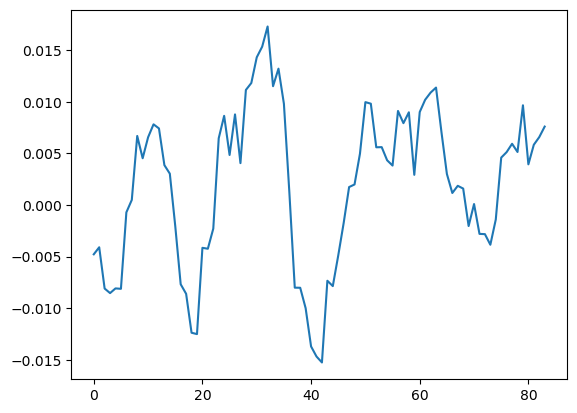

In [16]:
drps_cyc = rps_clim.reshape((15,84)).mean(axis=0) - rps.reshape((15,84)).mean(axis=0)
print(drps_cyc.mean())
plt.plot(drps_cyc)

In [12]:
lofo_rps = np.array([0.223812963332058584, 0.22221936022624986])
lofo_importances = lofo_rps - rps_valid
df_importances = pd.Series(
    lofo_importances, index=df_features_sel.columns
)

Text(0.5, 0, 'Increase in RPS')

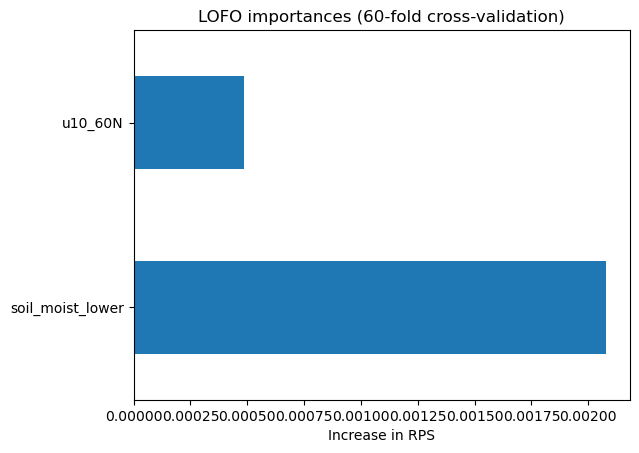

In [13]:
ax = df_importances.plot.barh()
ax.set_title("LOFO importances (60-fold cross-validation)")
ax.set_xlabel("Increase in RPS")
#plt.savefig('SEE_temp_terc_lofo_valid.png', bbox_inches = 'tight')

In [14]:
lofo_rps_test = np.zeros(2)
for i in range(2):

    leave_out = df_features_sel.columns[i]
    df_features_new = df_features_sel.drop(columns=leave_out)
    X_train = df_features_new[df_features_new.index < "2010-07"].values
    X_test = df_features_new[df_features_new.index >= "2010-07"].values
    
    classifier = RandomForestClassifier(n_estimators=1000, criterion='entropy', max_depth=None, min_samples_leaf=900, random_state=42)
    classifier.fit(X_train, y_train)

    y_pred = classifier.predict_proba(X_test)
    rps = ranked_probability_scores(y_test, y_pred)
    lofo_rps_test[i] = rps.mean()

In [15]:
lofo_importances_test = lofo_rps_test - 0.22024480500296567
df_importances_test = pd.Series(
    lofo_importances_test, index=df_features_sel.columns
)

Text(0.5, 0, 'Increase in RPS')

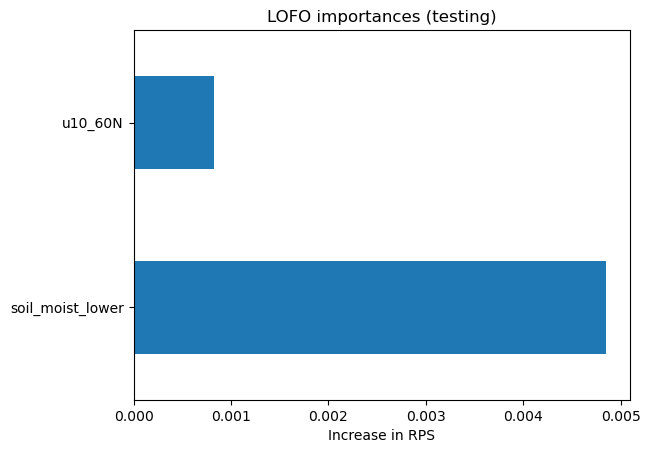

In [16]:
ax = df_importances_test.plot.barh()
ax.set_title("LOFO importances (testing)")
ax.set_xlabel("Increase in RPS")
#plt.savefig('SEE_temp_terc_lofo_test.png', bbox_inches = 'tight')

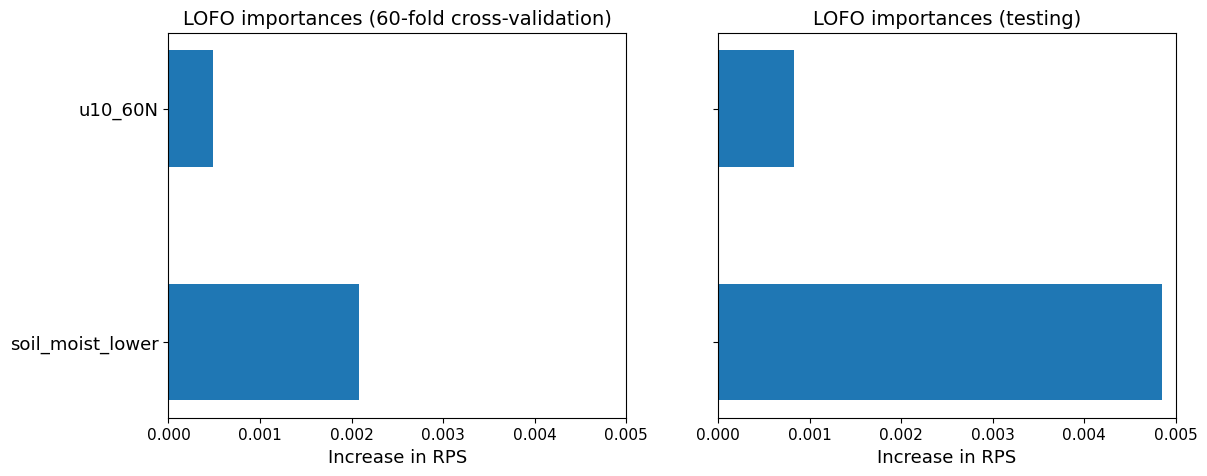

In [17]:
fig, ax = plt.subplots(1,2,figsize=(13,5))

ax[0].barh(df_importances.index, df_importances.values, 0.5)
ax[0].tick_params('y',labelsize=13)
ax[0].tick_params('x',labelsize=11)
ax[0].set_title("LOFO importances (60-fold cross-validation)", fontsize=14)
ax[0].set_xlabel("Increase in RPS", fontsize=13)
ax[0].set_xlim((0, 0.005))
#ax[0].vlines(0, -0.4, 2.4, 'k', '--')
#ax[0].set_ylim((-0.4, 2.4))

ax[1].barh(df_importances_test.index, df_importances_test.values, 0.5, tick_label=['',''])
ax[1].tick_params('x',labelsize=11)
ax[1].set_title("LOFO importances (testing)", fontsize=14)
ax[1].set_xlabel("Increase in RPS", fontsize=13)
ax[1].set_xlim((0, 0.005))
#ax[1].vlines(0, -0.4, 2.4, 'k', '--')
#ax[1].set_ylim((-0.4, 2.4))

plt.savefig('SEE_temp_terc_lofo.pdf', bbox_inches = 'tight')